In [9]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Taxi-v4")

print("State space:", env.observation_space)
print("Action space:", env.action_space)

State space: Discrete(500)
Action space: Discrete(6)


In [15]:
q_table = np.zeros(
    (env.observation_space.n, env.action_space.n)
)

learning_rate = 0.7
discount_factor = 0.95
epsilon = 1.0

epsilon_decay = 0.995
min_epsilon = 0.01

episodes = 10000
max_steps = 200

rewards_per_episode = []

In [17]:
for episode in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):
        # Epsilon-greedy action selection
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, terminated, truncated, info = (
            env.step(action)
        )

        # Q-learning update
        best_next_action = np.max(q_table[next_state])

        q_table[state, action] += learning_rate * (
            reward
            + discount_factor * best_next_action
            * (not terminated)
            - q_table[state, action]
        )

        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    epsilon = max(
        min_epsilon,
        epsilon * epsilon_decay
    )

    rewards_per_episode.append(total_reward)

print("Training completed!")
print("Final exploration rate:", round(epsilon, 4))

Training completed!
Final exploration rate: 0.01


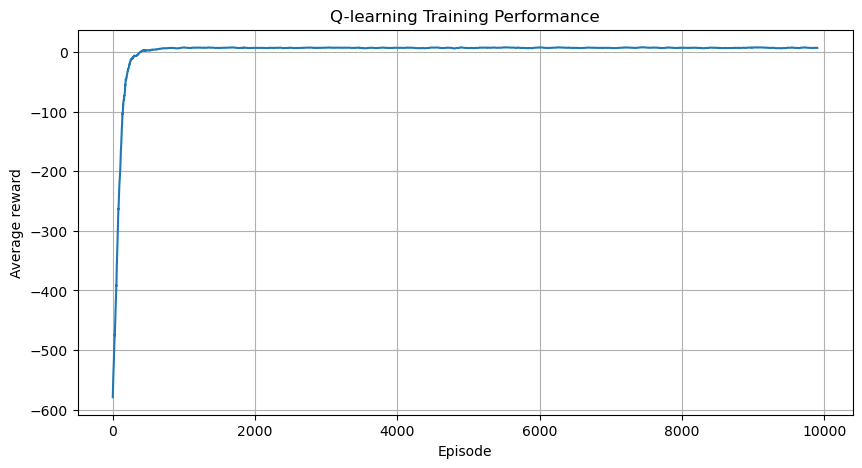

In [19]:
window = 100

moving_average = np.convolve(
    rewards_per_episode,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))
plt.plot(moving_average)
plt.xlabel("Episode")
plt.ylabel("Average reward")
plt.title("Q-learning Training Performance")
plt.grid(True)
plt.show()

In [23]:
test_env = gym.make("Taxi-v4", render_mode="ansi")

state, info = test_env.reset(seed=42)
total_reward = 0

for step in range(100):
    action = np.argmax(q_table[state])

    next_state, reward, terminated, truncated, info = (
        test_env.step(action)
    )

    state = next_state
    total_reward += reward

    print(test_env.render())

    if terminated or truncated:
        break

print("Total test reward:", total_reward)
print("Steps taken:", step + 1)

test_env.close()
env.close()

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

+---------+
|R: | : :G|
| : | : :_|
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | :_: |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

+---------+
|R: | : :G|
| : | : : |
| : : :_: |
| | : | : |
|Y| : |B: |
+---------+
  (South)

+---------+
|R: | : :G|
| : | : : |
| : :_: : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

+---------+
|R: | : :G|
| : | : : |
| :_: : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

+---------+
|R: | : :G|
| : | : : |
|_: : : : |
| | : | : |
|Y| : |B: |
+---------+
  (West)

+---------+
|R: | : :G|
| : | : : |
| : : : : |
|_| :